# 06 · Boosting: from AdaBoost to gradient boosting

AdaBoost (last notebook) built shallow trees one after the other, each one focused on the rows the previous ones got wrong. **Gradient boosting** keeps the idea of adding trees one at a time, but changes *what each new tree learns*: instead of re-weighting rows, every tree fits the **gradient of the loss**, i.e. how far, and in which direction, each row's current prediction should move.

This notebook:
1. builds gradient boosting **by hand** (3 trees) and checks it against scikit-learn's;
2. shows **how it overfits** and the settings that stop it (`learning_rate`, `n_estimators`, tree depth, `subsample`);
3. introduces **`HistGradientBoostingClassifier`**, the same algorithm on binned features: much faster, and it handles missing values itself;
4. adds both models to the pipeline;

The next notebook (`07_metrics`) changes *how* every model is evaluated.

## 1 · Setup

In [1]:
import time
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import yaml
from category_encoders import CountEncoder
from sklearn.compose import ColumnTransformer
from sklearn.datasets import make_classification
from sklearn.dummy import DummyClassifier
from sklearn.ensemble import (
    AdaBoostClassifier, BaggingClassifier, GradientBoostingClassifier, HistGradientBoostingClassifier,
    RandomForestClassifier,
)
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import log_loss, roc_auc_score, recall_score, precision_score
from sklearn.model_selection import StratifiedKFold, train_test_split
from sklearn.naive_bayes import GaussianNB
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import (
    OneHotEncoder, OrdinalEncoder, TargetEncoder, StandardScaler, MinMaxScaler, RobustScaler,
)
from sklearn.random_projection import SparseRandomProjection
from sklearn.tree import DecisionTreeClassifier, DecisionTreeRegressor
from sklearn.utils.class_weight import compute_sample_weight

PIPELINE_DIR = Path("../baseline-pipeline")    # only the data file is read from the pipeline folder

The parts of `config.yaml` this notebook uses, written out so the notebook runs on its own:

In [2]:
CONFIG_YAML = """
data:
  path: "data/compas_two_year_recidivism.csv"
  target: "two_year_recid"
  sensitive_attr: "race"                            # never a feature; used only for the fairness report
  drop_columns: ["id", "decile_score", "score_text"]  # kept in the data, never used as features

# Locked test set: never used to fit, tune or choose anything. Do not change once set.
test_set:
  size: 0.2
  random_state: 42

cv:
  n_splits: 5
  shuffle: true
  random_state: 42
  # Reported for every run. fbeta_<beta> weights recall beta times as much as precision.
  metrics: ["accuracy", "balanced_accuracy", "precision", "recall", "f1", "fbeta_2", "roc_auc", "average_precision"]
  selection_metric: "roc_auc"                       # one of metrics: what tuning maximises and runs are ranked by
  n_jobs: 1                                         # -1 = all CPU cores

diagnostics:
  id_column: "id"
  numeric_text_columns: ["priors_count", "prior_offenses"]
  # "nan" catches real NaNs turned into text by the category cleanup.
  placeholder_tokens: ["-", "?", "n/a", "N/A", "na", "NA", "", "nan"]
  validity_rules:
    age: {min: 18, max: 100}
    decile_score: {min: 1, max: 10}
    juv_fel_count: {min: 0}
    priors_count: {min: 0, max: 60}
  canonical_categories:
    sex:
      male: "Male"
      female: "Female"
    race:
      african-american: "African-American"
      african american: "African-American"
      caucasian: "Caucasian"
      hispanic: "Hispanic"
      other: "Other"
      asian: "Asian"
      native american: "Native American"
    c_charge_degree:
      f: "F"
      felony: "F"
      m: "M"
      misdemeanor: "M"
    score_text:
      low: "Low"
      medium: "Medium"
      high: "High"
  redundant_columns: ["prior_offenses", "age_in_months", "juvenile_total"]

preprocessing:
  encoder: "target"                                 # onehot | ordinal | count | target
  scaler: "robust"                                  # none | standard | minmax | robust
  numeric_features: ["age", "juv_fel_count", "juv_misd_count", "juv_other_count", "priors_count"]
  categorical_features: ["sex", "age_cat", "c_charge_degree"]
  mnar_indicator_sources: ["priors_count", "c_charge_degree"]   # get a <col>_was_missing flag
  random_state: 42                                  # target encoder's internal folds
  imputation:
    numeric_strategy: "median"
    categorical_strategy: "most_frequent"
"""
config = yaml.safe_load(CONFIG_YAML)

The pipeline functions from earlier weeks, **unchanged** (`src/preprocessing.py`, `src/model.py`):

In [3]:
def flag_invalid_values(df: pd.DataFrame, rules: dict) -> pd.DataFrame:
    """
    Applies {column: {"min": ..., "max": ...}} domain rules (either bound optional) and sets
    violations to NaN, in place. Returns the number of violations per column.
    """
    report_rows = []
    for column, bounds in rules.items():
        if column not in df.columns:
            continue
        numeric = pd.to_numeric(df[column], errors="coerce")
        lower_ok = numeric >= bounds["min"] if "min" in bounds else pd.Series(True, index=numeric.index)
        upper_ok = numeric <= bounds["max"] if "max" in bounds else pd.Series(True, index=numeric.index)
        violations = numeric.notna() & ~(lower_ok & upper_ok)
        report_rows.append({"column": column, "rule": bounds, "violations": int(violations.sum())})
        df.loc[violations, column] = np.nan
    return pd.DataFrame(report_rows)


def _canonicalize_categories(df: pd.DataFrame, columns_and_maps: dict, placeholder_tokens: set) -> pd.DataFrame:
    out = df.copy()
    for col, mapping in columns_and_maps.items():
        if col not in out.columns:
            continue
        cleaned = out[col].astype(str).str.strip()
        lowered = cleaned.str.lower()
        out[col] = lowered.map(mapping).fillna(cleaned)
        out.loc[out[col].astype(str).str.strip().isin(placeholder_tokens), col] = np.nan
    return out


def clean_dataset(df: pd.DataFrame, diagnostics_config: dict) -> pd.DataFrame:
    """
    Applies the cleaning rules in `diagnostics_config`: placeholder tokens and domain-rule
    violations become NaN, category spellings are canonicalized and redundant columns are
    dropped. Row-preserving and target-agnostic, so it runs unchanged on data to predict.
    """
    out = df.copy()
    placeholder_tokens = set(diagnostics_config.get("placeholder_tokens", []))

    for col in diagnostics_config.get("numeric_text_columns", []):
        if col in out.columns:
            out[col] = pd.to_numeric(out[col].replace(list(placeholder_tokens), np.nan), errors="coerce")

    flag_invalid_values(out, diagnostics_config.get("validity_rules", {}))
    out = _canonicalize_categories(out, diagnostics_config.get("canonical_categories", {}), placeholder_tokens)

    columns_to_drop = [c for c in diagnostics_config.get("redundant_columns", []) if c in out.columns]
    return out.drop(columns=columns_to_drop)


def drop_duplicate_rows(df: pd.DataFrame, id_column: str = None) -> pd.DataFrame:
    """
    Training data only, before `split_dev_test`: drops exact duplicate rows and repeated ids
    (keeping the first). Never call it on data to predict: every row needs a prediction.
    """
    out = df.drop_duplicates()
    if id_column and id_column in out.columns:
        out = out.drop_duplicates(subset=id_column, keep="first")
    return out


def add_missingness_indicators(df: pd.DataFrame, mnar_indicator_sources: list) -> pd.DataFrame:
    """Adds a `<col>_was_missing` flag for each listed column, before it is imputed."""
    out = df.copy()
    for col in mnar_indicator_sources:
        if col in out.columns:
            out[f"{col}_was_missing"] = out[col].isna().astype(int)
    return out


def split_features_target(df: pd.DataFrame, data_config: dict, mnar_indicator_sources: list):
    """
    Returns (X, y, extras). `extras` holds the columns kept out of the features for auditing
    (the sensitive attribute and COMPAS's own score). On label-free data `y` is None.
    """
    target = data_config["target"]
    sensitive_attr = data_config["sensitive_attr"]
    drop_columns = data_config.get("drop_columns", [])

    df = add_missingness_indicators(df, mnar_indicator_sources)
    y = df[target] if target in df.columns else None

    extras_cols = [c for c in [sensitive_attr, "score_text"] if c in df.columns]
    extras = df[extras_cols].copy() if extras_cols else None

    always_drop = set(drop_columns) | {target, sensitive_attr}
    feature_cols = [c for c in df.columns if c not in always_drop]
    return df[feature_cols], y, extras


_SCALERS = {"none": "passthrough", "standard": StandardScaler, "minmax": MinMaxScaler, "robust": RobustScaler}


# sklearn's TargetEncoder cross-fits: a training row's encoding never uses its own label.
_ENCODERS = {
    "onehot": lambda seed: OneHotEncoder(handle_unknown="ignore", sparse_output=False),
    "ordinal": lambda seed: OrdinalEncoder(handle_unknown="use_encoded_value", unknown_value=-1),
    "count": lambda seed: CountEncoder(handle_unknown=0, handle_missing=0),
    "target": lambda seed: TargetEncoder(target_type="binary", cv=StratifiedKFold(5, shuffle=True, random_state=seed)),
}


def build_preprocessor(preprocessing_config: dict) -> ColumnTransformer:
    """
    Builds the unfitted ColumnTransformer described by `preprocessing_config`: imputation and
    scaling for numeric columns, imputation and encoding for categorical ones, and the
    missingness flags passed through. Every encoder tolerates unseen categories.
    """
    imputation = preprocessing_config.get("imputation", {})
    scaler_factory = _SCALERS[preprocessing_config["scaler"]]
    scaler = scaler_factory() if callable(scaler_factory) else scaler_factory
    encoder = _ENCODERS[preprocessing_config["encoder"]](preprocessing_config.get("random_state"))

    numeric_pipeline = Pipeline([
        ("impute", SimpleImputer(strategy=imputation.get("numeric_strategy", "median"))),
        ("scale", scaler),
    ])
    categorical_pipeline = Pipeline([
        ("impute", SimpleImputer(strategy=imputation.get("categorical_strategy", "most_frequent"))),
        ("encode", encoder),
    ])
    indicator_cols = [f"{c}_was_missing" for c in preprocessing_config.get("mnar_indicator_sources", [])]

    return ColumnTransformer([
        ("numeric", numeric_pipeline, preprocessing_config["numeric_features"]),
        ("categorical", categorical_pipeline, preprocessing_config["categorical_features"]),
        ("indicators", "passthrough", indicator_cols),
    ])


def split_dev_test(X, y, extras, test_size: float, random_state: int):
    """
    Stratified split into a development set, used for every decision, and a locked test set,
    used only for the final assessment. Returns X_dev, X_test, y_dev, y_test, extras_dev,
    extras_test, row-aligned.
    """
    return train_test_split(X, y, extras, test_size=test_size, random_state=random_state, stratify=y)


def adaboost(max_depth: int = 1, **params):
    """
    AdaBoost over decision trees of depth `max_depth` (1 = stumps); `params` go to
    AdaBoostClassifier. The trees' depth is tuned as `model__estimator__max_depth`.
    """
    return AdaBoostClassifier(estimator=DecisionTreeClassifier(max_depth=max_depth), **params)


def oblique_random_forest(n_estimators: int = 100, n_components: int = 10, density="auto",
                          random_state=None, n_jobs=None, **tree_params):
    """
    A forest of oblique trees: each tree is fit on a bootstrap sample, on `n_components`
    random sparse linear combinations of the features (a new set per tree), so its splits are
    hyperplanes. `tree_params` go to every tree (`max_features` defaults to "sqrt"). Tuned as
    `model__estimator__tree__<param>` and `model__estimator__project__<param>`.
    """
    tree_params.setdefault("max_features", "sqrt")
    oblique_tree = Pipeline([
        ("project", SparseRandomProjection(n_components=n_components, density=density)),
        ("tree", DecisionTreeClassifier(**tree_params)),
    ])
    return BaggingClassifier(estimator=oblique_tree, n_estimators=n_estimators,
                             random_state=random_state, n_jobs=n_jobs)


_MODELS = {
    "dummy": DummyClassifier,
    "logistic_regression": LogisticRegression,
    "decision_tree": DecisionTreeClassifier,
    "random_forest": RandomForestClassifier,
    "oblique_random_forest": oblique_random_forest,
    "adaboost": adaboost,
}


def build_model(model_config: dict):
    """Builds the model named by `model_config["type"]` with `model_config["params"]`."""
    model_type = model_config["type"]
    params = model_config.get("params") or {}

    if model_type not in _MODELS:
        raise ValueError(f"Unknown model type: {model_type}. Options: {list(_MODELS)}")

    return _MODELS[model_type](**params)


def build_pipeline(preprocessing_config: dict, model_config: dict) -> Pipeline:
    """
    The estimator that is cross-validated, tuned and refit: preprocessing and model as one
    Pipeline, so every learned step is re-fit on the training part of each fold. Step names
    address hyperparameters from outside (`model__max_depth`, `prep__numeric__impute__strategy`).
    Any new learned step (e.g. feature selection) belongs here, between "prep" and "model".
    """
    return Pipeline([
        ("prep", build_preprocessor(preprocessing_config)),
        ("model", build_model(model_config)),
    ])

The data, cleaned and split exactly as `main.py` does it. The by-hand demos use the **first fold** of the pipeline's CV: preprocessing fitted on its training part only, then applied to its validation part.

In [4]:
df_raw = pd.read_csv(PIPELINE_DIR / config["data"]["path"])
df_clean = clean_dataset(df_raw, config["diagnostics"])
df_clean = drop_duplicate_rows(df_clean, config["diagnostics"].get("id_column"))
X, y, extras = split_features_target(df_clean, config["data"], config["preprocessing"]["mnar_indicator_sources"])
X_dev, X_test, y_dev, y_test, extras_dev, extras_test = split_dev_test(
    X, y, extras, test_size=config["test_set"]["size"], random_state=config["test_set"]["random_state"])

cv = StratifiedKFold(n_splits=config["cv"]["n_splits"], shuffle=config["cv"]["shuffle"],
                     random_state=config["cv"]["random_state"])
train_idx, val_idx = next(cv.split(X_dev, y_dev))
prep = build_preprocessor(config["preprocessing"])
X_tr = prep.fit_transform(X_dev.iloc[train_idx], y_dev.iloc[train_idx])
X_va = prep.transform(X_dev.iloc[val_idx])
y_tr, y_va = y_dev.iloc[train_idx].to_numpy(), y_dev.iloc[val_idx].to_numpy()
feature_names = prep.get_feature_names_out()
print(f"development set: {len(X_dev)} rows · fold 1: {len(y_tr)} training rows, {len(y_va)} validation rows")
print(f"{X_tr.shape[1]} features after preprocessing · base rate (share who reoffended): {y_tr.mean():.3f}")

development set: 5771 rows · fold 1: 4616 training rows, 1155 validation rows
10 features after preprocessing · base rate (share who reoffended): 0.451


## 2 · From AdaBoost to gradient boosting

| | AdaBoost | Gradient boosting |
|---|---|---|
| What each new tree sees | the original labels, with **row weights** raised on the rows the ensemble got wrong | a new target for every row: the **negative gradient** of the loss (how much its prediction should move) |
| The new tree | a classifier (votes ±1) | a **regression** tree, even for classification |
| How trees combine | weighted vote | **sum** of the trees' outputs (in log-odds), each scaled by `learning_rate` |
| Loss | exponential (built in) | any differentiable loss: log-loss for classification, squared error for regression, … |

For classification with log-loss, the model's output for a row is a log-odds `F`, its probability is `p = sigmoid(F)`, and the negative gradient of the log-loss with respect to `F` is simply

$$ r = y - p $$

the **residual**: +0.9 for a reoffender given p = 0.1, −0.9 for a non-reoffender given p = 0.9, near 0 for rows already predicted well. So the rows the ensemble gets most wrong get the largest targets, the same intuition as AdaBoost's weights, but written for any loss. That's why gradient boosting is the general form of boosting.

![GB](https://media.geeksforgeeks.org/wp-content/uploads/20250903173429506712/des.webp)

## 3 · Gradient boosting by hand: 3 trees

Each round:
1. **probabilities** from the current log-odds: `p = sigmoid(F)`; the start, `F₀`, is the log-odds of the base rate (one number for every row);
2. **residuals** `r = y − p`;
3. fit a small **regression tree** to the residuals (here depth 2, so 4 leaves);
4. each leaf's value is one **Newton step**, `Σr / Σp(1−p)` over the leaf's rows (the residual, scaled by how sure the model already is);
5. **update** `F ← F + learning_rate × leaf value`.

In [5]:
learning_rate, n_rounds, depth = 0.5, 3, 2
sigmoid = lambda F: 1 / (1 + np.exp(-F))

F_tr = np.full(len(y_tr), np.log(y_tr.mean() / (1 - y_tr.mean())))   # F0: log-odds of the base rate
F_va = np.full(len(y_va), F_tr[0])
print(f"round 0: every row gets p = {sigmoid(F_tr[0]):.3f}   train log-loss {log_loss(y_tr, sigmoid(F_tr)):.4f}   "
      f"validation log-loss {log_loss(y_va, sigmoid(F_va)):.4f}")

for m in range(1, n_rounds + 1):
    p = sigmoid(F_tr)
    residual = y_tr - p
    tree = DecisionTreeRegressor(max_depth=depth, criterion="squared_error", random_state=0).fit(X_tr, residual)
    leaf_tr, leaf_va = tree.apply(X_tr), tree.apply(X_va)
    leaf_value = {leaf: residual[leaf_tr == leaf].sum() / (p[leaf_tr == leaf] * (1 - p[leaf_tr == leaf])).sum()
                  for leaf in np.unique(leaf_tr)}
    F_tr = F_tr + learning_rate * np.array([leaf_value[l] for l in leaf_tr])
    F_va = F_va + learning_rate * np.array([leaf_value[l] for l in leaf_va])
    print(f"round {m}: tree splits on {[feature_names[f] for f in tree.tree_.feature if f >= 0]}")
    print(f"         leaf values (log-odds): {np.round(list(leaf_value.values()), 3)}   "
          f"train log-loss {log_loss(y_tr, sigmoid(F_tr)):.4f}   validation log-loss {log_loss(y_va, sigmoid(F_va)):.4f}")

round 0: every row gets p = 0.451   train log-loss 0.6883   validation log-loss 0.6884
round 1: tree splits on ['numeric__priors_count', 'numeric__age', 'numeric__age']
         leaf values (log-odds): [ 0.464 -0.595  1.105  0.336]   train log-loss 0.6446   validation log-loss 0.6447
round 2: tree splits on ['numeric__priors_count', 'numeric__age', 'numeric__age']
         leaf values (log-odds): [ 0.06  -0.508  1.001  0.556]   train log-loss 0.6262   validation log-loss 0.6303
round 3: tree splits on ['numeric__priors_count', 'numeric__age', 'categorical__age_cat']
         leaf values (log-odds): [ 0.809 -0.349  0.131  0.908]   train log-loss 0.6142   validation log-loss 0.6196


scikit-learn's `GradientBoostingClassifier` with the same settings gives the same probabilities, to the last digit:

In [6]:
gb = GradientBoostingClassifier(n_estimators=n_rounds, max_depth=depth, learning_rate=learning_rate,
                                random_state=0).fit(X_tr, y_tr)
print("largest difference in validation probabilities:", np.abs(sigmoid(F_va) - gb.predict_proba(X_va)[:, 1]).max())

largest difference in validation probabilities: 1.1102230246251565e-16


Two things to keep from this:
- the trees are **regression** trees on residuals, and the model's output is a **sum** of their leaf values (log-odds), turned into a probability at the end;
- every tree only *corrects* the trees before it. Nothing stops it from correcting noise: that's the overfitting risk of the next section.

## 4 · How gradient boosting overfits, and the settings that stop it

In a random forest, more trees never overfit: the trees are independent and their average only gets more stable. In gradient boosting, every tree fits **what the previous trees left**, so after the real signal is captured, new trees start fitting the noise. More trees *can* overfit, and **`n_estimators` must be tuned together with `learning_rate`**:
- **`learning_rate`** shrinks each tree's contribution. A smaller step needs more trees but generalises better;
- **tree depth**: boosting wants **shallow** trees (weak learners). A depth-`d` tree models interactions of up to `d` features; depth 8 already memorises;
- **`subsample` < 1** fits each tree on a random share of the rows (*stochastic* gradient boosting): less variance, and faster.

The curves below follow one model as trees are added (`staged_predict_proba` gives the prediction after 1, 2, …, 300 trees), on fold 1: train log-loss dashed, validation log-loss solid.

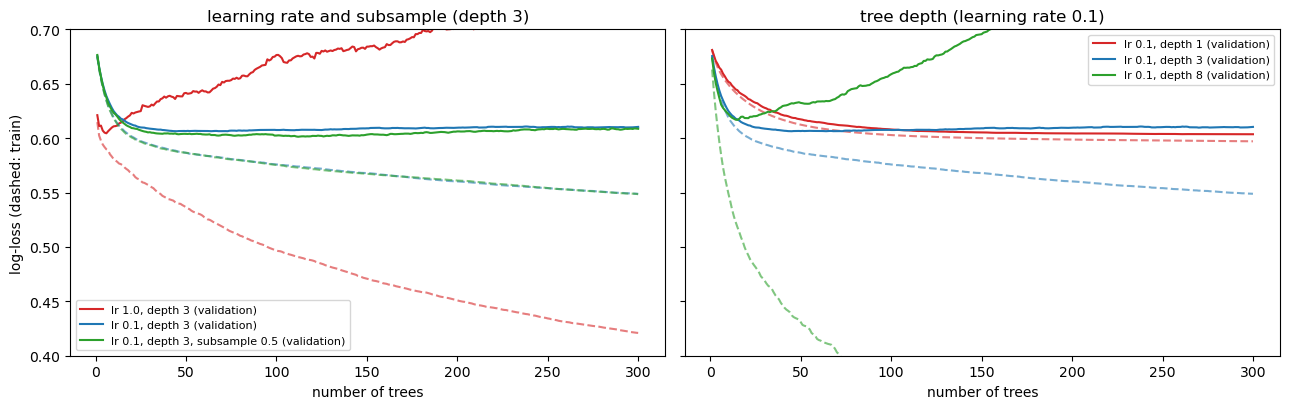

,setting,best number of trees,validation log-loss at best,validation log-loss at 300,train log-loss at 300
0,"lr 1.0, depth 3",6,0.6044,0.7512,0.4210
1,"lr 0.1, depth 3",45,0.6063,0.6103,0.5488
2,"lr 0.1, depth 3, subsample 0.5",112,0.6013,0.6086,0.5484
3,"lr 0.1, depth 1",288,0.6036,0.6036,0.5971
4,"lr 0.1, depth 8",15,0.6168,0.8328,0.2382


In [7]:
settings = {
    "lr 1.0, depth 3":  dict(learning_rate=1.0, max_depth=3),
    "lr 0.1, depth 3":  dict(learning_rate=0.1, max_depth=3),
    "lr 0.1, depth 3, subsample 0.5": dict(learning_rate=0.1, max_depth=3, subsample=0.5),
    "lr 0.1, depth 1":  dict(learning_rate=0.1, max_depth=1),
    "lr 0.1, depth 8":  dict(learning_rate=0.1, max_depth=8),
}
n_trees = 300
curves, rows = {}, []
for name, params in settings.items():
    model = GradientBoostingClassifier(n_estimators=n_trees, random_state=42, **params).fit(X_tr, y_tr)
    train = [log_loss(y_tr, p[:, 1]) for p in model.staged_predict_proba(X_tr)]
    val = [log_loss(y_va, p[:, 1]) for p in model.staged_predict_proba(X_va)]
    curves[name] = (train, val)
    best = int(np.argmin(val))
    rows.append({"setting": name, "best number of trees": best + 1, "validation log-loss at best": val[best],
                 f"validation log-loss at {n_trees}": val[-1], f"train log-loss at {n_trees}": train[-1]})

fig, axes = plt.subplots(1, 2, figsize=(13, 4.2), sharey=True)
for ax, names in zip(axes, [["lr 1.0, depth 3", "lr 0.1, depth 3", "lr 0.1, depth 3, subsample 0.5"],
                            ["lr 0.1, depth 1", "lr 0.1, depth 3", "lr 0.1, depth 8"]]):
    for name, color in zip(names, ["tab:red", "tab:blue", "tab:green"]):
        train, val = curves[name]
        ax.plot(range(1, n_trees + 1), val, color=color, label=f"{name} (validation)")
        ax.plot(range(1, n_trees + 1), train, color=color, ls="--", alpha=0.6)
    ax.set_xlabel("number of trees"); ax.legend(fontsize=8); ax.set_ylim(0.4, 0.7)
axes[0].set_ylabel("log-loss (dashed: train)")
axes[0].set_title("learning rate and subsample (depth 3)"); axes[1].set_title("tree depth (learning rate 0.1)")
plt.tight_layout(); plt.show()
pd.DataFrame(rows).round(4)

How to read it:
- **learning rate 1.0** reaches its best validation loss within a few trees, then gets worse with every tree added, while the train loss keeps falling. That's overfitting caused by too many trees, which a random forest can't do;
- **learning rate 0.1** gets to a similar (or better) best, more slowly, and stays near it much longer: the number of trees matters less;
- **depth 8** memorises the training rows (train loss collapses) and is the worst on validation from early on; **stumps** (depth 1) learn slowly but safely;
- `subsample` 0.5 reaches the lowest validation loss of all, with more trees: each tree sees a different half of the rows, which adds a little randomness and acts as regularisation.

So tuning gradient boosting means tuning `n_estimators`, `learning_rate` and depth **together**: they trade off against each other. The pipeline's search space does exactly that (section 6).

## 5 · `HistGradientBoostingClassifier`: the same algorithm, binned

![HGB](https://encrypted-tbn0.gstatic.com/images?q=tbn:ANd9GcR-0I5f6zdy1osaQysuaDdKOrunmZLbUopaQGd_13vZXS_u8Eqfo_dPZsQs&s=10)

Same idea as section 3 (trees fit to gradients, Newton leaf values, a learning rate), with three engineering changes that matter on large data:
- **binning**: before training, every feature is cut into at most 255 quantile bins, once. A split search then scans 255 bins instead of every sorted value, so the cost barely grows with the number of rows;
- **missing values** are handled natively: at each split it learns which side rows with a missing value should go;
- trees are grown **leaf by leaf** up to `max_leaf_nodes` (31 by default) instead of level by level up to `max_depth`, and there is an `l2_regularization` on the leaf values. `max_iter` plays the role of `n_estimators`; with more than 10,000 rows, early stopping is on by default.

On COMPAS (4,616 training rows) both are fast. On 50,000 rows, the difference is the binning:

In [8]:
X_big, y_big = make_classification(n_samples=50_000, n_features=20, n_informative=10, random_state=42)
rows = []
for data_name, (Xa, ya) in {"COMPAS fold 1": (X_tr, y_tr), "50,000 synthetic rows": (X_big, y_big)}.items():
    for name, model in [("GradientBoostingClassifier", GradientBoostingClassifier(n_estimators=100, max_depth=3, random_state=42)),
                        ("HistGradientBoostingClassifier", HistGradientBoostingClassifier(max_iter=100, early_stopping=False,
                                                                                          random_state=42))]:
        start = time.perf_counter()
        model.fit(Xa, ya)
        rows.append({"data": data_name, "model": name, "fit time (s)": time.perf_counter() - start})
pd.DataFrame(rows).pivot(index="model", columns="data", values="fit time (s)").round(2)

c:\ProgramData\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py:136: UserWarning: Could not find the number of physical cores for the following reason:
[WinError 2] The system cannot find the file specified
Returning the number of logical cores instead. You can silence this warning by setting LOKY_MAX_CPU_COUNT to the number of cores you want to use.
  warnings.warn(
  File "c:\ProgramData\anaconda3\Lib\site-packages\joblib\externals\loky\backend\context.py", line 257, in _count_physical_cores
    cpu_info = subprocess.run(
               ^^^^^^^^^^^^^^^
  File "c:\ProgramData\anaconda3\Lib\subprocess.py", line 548, in run
    with Popen(*popenargs, **kwargs) as process:
         ^^^^^^^^^^^^^^^^^^^^^^^^^^^
  File "c:\ProgramData\anaconda3\Lib\subprocess.py", line 1026, in __init__
    self._execute_child(args, executable, preexec_fn, close_fds,
  File "c:\ProgramData\anaconda3\Lib\subprocess.py", line 1538, in _execute_child
    hp, ht, pid, tid = _winapi.CreatePro

data,"50,000 synthetic rows",COMPAS fold 1
model,,
GradientBoostingClassifier,29.38,0.32
HistGradientBoostingClassifier,0.50,0.28


Missing values: `HistGradientBoostingClassifier` trains on the raw numeric columns, gaps and all; `GradientBoostingClassifier` refuses them:

In [9]:
numeric = config["preprocessing"]["numeric_features"]
X_raw_tr = X_dev.iloc[train_idx][numeric]
print("missing values in the raw training columns:", X_raw_tr.isna().sum().to_dict())

HistGradientBoostingClassifier(random_state=42).fit(X_raw_tr, y_tr)
print("HistGradientBoostingClassifier: fitted")
try:
    GradientBoostingClassifier(random_state=42).fit(X_raw_tr, y_tr)
except ValueError as error:
    print("GradientBoostingClassifier:", str(error).split(".")[0])

missing values in the raw training columns: {'age': 93, 'juv_fel_count': 137, 'juv_misd_count': 0, 'juv_other_count': 0, 'priors_count': 325}
HistGradientBoostingClassifier: fitted
GradientBoostingClassifier: Input X contains NaN


The pipeline still imputes before every model: the missingness flags and the target encoder need complete columns, and every model then gets the same input, so their scores can be compared.

## 6 · The pipeline: two boosters and a Naive Bayes baseline

<div style="background-color:#e8f5e9; border-left:6px solid #2e7d32; padding:10px 14px; border-radius:4px"> <b>New in the pipeline: three model types in <code>_MODELS</code></b> &nbsp;·&nbsp; <code>src/model.py</code><br><code>gradient_boosting</code> and <code>hist_gradient_boosting</code> are the two boosters of this notebook. <code>naive_bayes</code> (<code>GaussianNB</code>) is a fast probabilistic baseline to compare the other models against. No new builder functions: scikit-learn's classes go straight in.</div>

In [10]:
_MODELS = {
    "dummy": DummyClassifier,
    "logistic_regression": LogisticRegression,
    "decision_tree": DecisionTreeClassifier,
    "random_forest": RandomForestClassifier,
    "oblique_random_forest": oblique_random_forest,
    "adaboost": adaboost,
    "gradient_boosting": GradientBoostingClassifier,
    "hist_gradient_boosting": HistGradientBoostingClassifier,
    "naive_bayes": GaussianNB,
}

The `model` section of `config.yaml` (gradient boosting is now the configured model) and the boosters' search spaces:

In [11]:
CONFIG_YAML = """
model:
  type: "gradient_boosting"  # dummy | logistic_regression | naive_bayes | decision_tree | random_forest | oblique_random_forest | adaboost | gradient_boosting | hist_gradient_boosting
  params:
    random_state: 42
  # Other models' params, to swap in. class_weight "balanced" weights each class by 1 / its frequency
  # (GradientBoostingClassifier and GaussianNB have no class_weight).
  # logistic_regression:    {max_iter: 2000, class_weight: balanced}
  # naive_bayes:            {}
  # decision_tree:          {random_state: 42, class_weight: balanced}
  # random_forest:          {n_estimators: 200, random_state: 42, n_jobs: -1, class_weight: balanced}
  # oblique_random_forest:  {n_estimators: 200, n_components: 10, random_state: 42, n_jobs: -1}
  # adaboost:               {max_depth: 1, n_estimators: 200, learning_rate: 1.0, random_state: 42}
  # hist_gradient_boosting: {random_state: 42, class_weight: balanced}

tuning:
  search_spaces:
    gradient_boosting:
      model__n_estimators: {type: int, low: 25, high: 500, log: true}
      model__learning_rate: {type: float, low: 0.01, high: 0.5, log: true}
      model__max_depth: {type: int, low: 1, high: 6}
      model__min_samples_leaf: {type: int, low: 1, high: 200, log: true}
      model__subsample: {type: float, low: 0.5, high: 1.0}
    hist_gradient_boosting:
      model__max_iter: {type: int, low: 25, high: 500, log: true}
      model__learning_rate: {type: float, low: 0.01, high: 0.5, log: true}
      model__max_leaf_nodes: {type: int, low: 2, high: 63, log: true}
      model__min_samples_leaf: {type: int, low: 5, high: 200, log: true}
      model__l2_regularization: {type: float, low: 0.000001, high: 10.0, log: true}
"""
model_config = yaml.safe_load(CONFIG_YAML)

In [12]:
print(model_config["model"])
pipeline = build_pipeline(config["preprocessing"], model_config["model"])
pipeline.fit(X_dev.iloc[train_idx], y_dev.iloc[train_idx])
print(f"fold 1, validation ROC-AUC: {roc_auc_score(y_va, pipeline.predict_proba(X_dev.iloc[val_idx])[:, 1]):.3f}")

{'type': 'gradient_boosting', 'params': {'random_state': 42}}
fold 1, validation ROC-AUC: 0.731


The search spaces follow section 4: the number of trees, the learning rate and the tree size are searched **together**, with `n_estimators` (`max_iter`) and `learning_rate` on a log scale. Tuned scores (nested CV) for every model are on the scoreboard in `07_metrics`.

## 7 · What this notebook adds to your pipeline

| File | What to add |
|---|---|
| `src/model.py` | the imports `GradientBoostingClassifier`, `HistGradientBoostingClassifier` (from `sklearn.ensemble`) and `GaussianNB` (from `sklearn.naive_bayes`); three entries in `_MODELS`: `gradient_boosting`, `hist_gradient_boosting`, `naive_bayes` (§6) |
| `config.yaml` | `model.type: "gradient_boosting"` with `params: {random_state: 42}`; a search space for each of the three models under `tuning.search_spaces` (§6) |

Nothing else changes here: how every model is *evaluated* changes in `07_metrics`. To check this part on its own, run `python main.py` with `tuning.enabled: false`: it should run gradient boosting end to end.

## 8 · Takeaways

- Gradient boosting adds **regression trees fit to the gradient of the loss**. For log-loss, that's the residual `y − p`, and the trees' outputs are summed in log-odds.
- Unlike a forest, **more trees can overfit**: tune `n_estimators`, `learning_rate` and depth together. Boosting wants shallow trees and small steps.
- `HistGradientBoostingClassifier` is the same algorithm on **binned** features: much faster on large data, handles missing values, grows trees leaf by leaf.
- In the pipeline: `gradient_boosting`, `hist_gradient_boosting` and `naive_bayes` in `_MODELS`, with search spaces in `config.yaml`. Next: `07_metrics`.